# Credit Risk Classification: Traditional ML vs. Deep Learning

## 1. Reproducibility and environment setup

The UCI dataset of Default of Credit Card Clients (30,000 data points before any cleaning) is used in this notebook. The goal is to determine if the client missed a payment the previous month. Download the data set from the UCI Machine Learning Repository, and save the csv to the configured `DATA_PATH`; In Google Colab, the optional Drive path below can be modified to your own copy.

The workflow consists of training 70%, validation 10%, test 20%. The validation set is only used for model selection, and the held-out test set is only used once at the end. The boosting of pre-processing is only applied to the training rows and then the same pre-processing is applied to the validation and test rows.

Note: this is a benchmark data set from Taiwan, not a sample of Rwandan borrowers. Results do not provide evidence of fairness, creditworthiness in other countries, causal effects, or lending readiness. Fairness and deployment claims must be independently validated, calibrated, cost analysed, reviewed for privacy/security, and observed by humans.


In [1]:
# Dependencies: pandas, numpy, scikit-learn, tensorflow, matplotlib, joblib
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import tensorflow as tf
import random
from tensorflow.keras import layers, models, metrics, callbacks

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/UCI_Credit_Card.csv'
    ZIP_PATH = '/content/drive/MyDrive/IML/Eloi_Iradukunda_Summative_Project/UCI_Credit_Card.zip'
    if os.path.exists(ZIP_PATH) and not os.path.exists(DATA_PATH):
        import zipfile
        with zipfile.ZipFile(ZIP_PATH) as zf:
            zf.extractall('/content/')
        # The official archive may contain an Excel file rather than a CSV.
        if not os.path.exists(DATA_PATH):
            for candidate in ['/content/default of credit card clients.xls', '/content/default of credit card clients.xlsx']:
                if os.path.exists(candidate):
                    DATA_PATH = candidate
                    break
except ImportError:
    DATA_PATH = os.environ.get('CREDIT_DATA_PATH', 'UCI_Credit_Card.csv')

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'Dataset not found at {DATA_PATH}. Download the UCI dataset and set DATA_PATH/CREDIT_DATA_PATH. '
        'Do not commit the raw dataset to GitHub.'
    )

if DATA_PATH.lower().endswith(('.xls', '.xlsx')):
    df = pd.read_excel(DATA_PATH)
else:
    df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.upper().str.strip()
if 'DEFAULT.PAYMENT.NEXT.MONTH' in df.columns:
    df = df.rename(columns={'DEFAULT.PAYMENT.NEXT.MONTH': 'default'})
elif 'DEFAULT PAYMENT NEXT MONTH' in df.columns:
    df = df.rename(columns={'DEFAULT PAYMENT NEXT MONTH': 'default'})
elif 'DEFAULT' in df.columns:
    df = df.rename(columns={'DEFAULT': 'default'})
print('Dataset shape before preprocessing:', df.shape)
print('Columns available:', df.columns.tolist())


Mounted at /content/drive
Dataset shape before preprocessing: (30001, 25)
Columns available: ['UNNAMED: 0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']


In [2]:
# Support either the official UCI descriptive column names or the compact X1..Y names.
column_mapping = {
    'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
    'X6': 'PAY_1', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
    'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3', 'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
    'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3', 'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6',
    'Y': 'default'
}
df = df.rename(columns=column_mapping)
if 'UNNAMED: 0' in df.columns:
    df = df.drop(columns=['UNNAMED: 0'])
if 'ID' not in df.columns and 'ID' in column_mapping.values():
    pass
if 'default' not in df.columns:
    raise ValueError('Target column not found. Expected DEFAULT.PAYMENT.NEXT.MONTH or Y.')
print('Renamed Columns:', df.columns.tolist())


Renamed Columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default']


In [3]:
# Convert all columns to numeric types.
df = df.apply(pd.to_numeric, errors='coerce')

# Drop any rows that contain NaN
df = df.dropna()

# Verify the data types are now numeric (float64 or int64)
print("Data types successfully converted:")
print(df[['LIMIT_BAL', 'BILL_AMT1', 'EDUCATION']].dtypes)

Data types successfully converted:
LIMIT_BAL    float64
BILL_AMT1    float64
EDUCATION    float64
dtype: object


## Data Cleaning: Handling Undocumented Categories
There are unrecorded categorical values in the UCI Credit Card dataset. Specifically, the EDUCATION feature includes classes 1-4, and the raw data includes 0, 5 and 6. In the same way, there is an unrecognized 0 in MARRIAGE. These are separate classes which add noise. These missing values are assigned to the "Other" class so that the data is not corrupted and the model does not acquire false patterns.

In [4]:
def clean_categorical_features(data):
    df_clean = data.copy()

    # EDUCATION: 1=Graduate School, 2=University, 3=High School, 4=Others
    # Group undocumented values (0, 5, 6) into 4 (Others)
    df_clean['EDUCATION'] = df_clean['EDUCATION'].apply(lambda x: 4 if x not in [1, 2, 3, 4] else x)

    # MARRIAGE: 1=Married, 2=Single, 3=Others
    # Group undocumented value (0) into 3 (Others)
    df_clean['MARRIAGE'] = df_clean['MARRIAGE'].apply(lambda x: 3 if x not in [1, 2, 3] else x)

    return df_clean

df = clean_categorical_features(df)

## Feature Engineering: Financial Ratios

Prior to splitting two features are extracted from the data that are domain motivated: row-wise transformations and do not estimate parameters from the full dataset:

1. The ratio of the amount of credit used to the credit limit is known as the credit utilization ratio.
2. Payment to bill ratio = previous payment/previous bill amount.

The denominator offset is small enough to prevent division by zero. The ratio of payment to bill is limited to [0, 1] in order to reduce the extreme values, but also to lose information when the payment is over the bill and when the bill is negative. This is a modeling option and not the financial definition that is universally valid. These engineered features are not guaranteed to enhance performance in the notebook unless there is an independent ablation study to substantiate this.


In [5]:
def engineer_financial_features(data):
    df_eng = data.copy()

    # 1. Credit Utilization Ratio (Most recent month)
    # Adding a small epsilon (1e-6) to prevent division by zero in edge cases
    df_eng['utilization_ratio_1'] = df_eng['BILL_AMT1'] / (df_eng['LIMIT_BAL'] + 1e-6)

    # 2. Payment-to-Bill Ratio (Previous month's payment vs previous month's bill)
    # How much of BILL_AMT2 was paid off by PAY_AMT1?
    df_eng['pay_ratio_1'] = df_eng['PAY_AMT1'] / (df_eng['BILL_AMT2'] + 1e-6)

    # Cap extreme infinite values that occur if a bill was 0 but a payment was made
    df_eng['pay_ratio_1'] = df_eng['pay_ratio_1'].clip(upper=1.0, lower=0.0)

    return df_eng

df = engineer_financial_features(df)

## Train / Validation / Test Split and Preprocessing

The stratified split is 20% for final test and 70% training and 10% validation. The target proportion is approximately maintained for every split using stratification. All learned preprocessing is only fit on the training split.

The ratios of monetary values, age and engineered ratios are robust-scaled. Few categories (such as SEX, EDUCATION, MARRIAGE) are nominal and have been one-hot encoded, but the models should not be interpreted as representing meaningful numeric distance between category codes. The numeric ordinal codes of payment-delay variables ( `PAY_1`–`PAY_6`) still require this assumption, which is a limitation that needs to be tested in future research. The encoder takes care of unknown nominal categories. The fitted `ColumnTransformer` and the order of the features are preserved for re-producibility.


In [6]:
# Separate target and features
X = df.drop(columns=['ID', 'default'], errors='ignore').copy()
y = df['default'].astype('int32')

# Deterministic row-wise engineering has already been applied; split before fitting preprocessing.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.125, random_state=SEED, stratify=y_train_val
)

nominal_features = ['SEX', 'EDUCATION', 'MARRIAGE']
continuous_features = [
    'LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2',
    'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
    'utilization_ratio_1', 'pay_ratio_1'
]
ordinal_features = [f'PAY_{i}' for i in range(1, 7)]

# Compatible with older and newer scikit-learn versions.
try:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('scaled_continuous', RobustScaler(), continuous_features),
        ('nominal_onehot', onehot, nominal_features),
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

X_train_arr = preprocessor.fit_transform(X_train)
X_val_arr = preprocessor.transform(X_val)
X_test_arr = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out().tolist()
X_train_scaled = pd.DataFrame(X_train_arr, columns=feature_names, index=X_train.index)
X_val_scaled = pd.DataFrame(X_val_arr, columns=feature_names, index=X_val.index)
X_test_scaled = pd.DataFrame(X_test_arr, columns=feature_names, index=X_test.index)

print('Training rows:', len(X_train))
print('Validation rows:', len(X_val))
print('Testing rows:', len(X_test))
print('\nDefault rates:')
print('Train:', round(y_train.mean(), 4))
print('Validation:', round(y_val.mean(), 4))
print('Test:', round(y_test.mean(), 4))
print('\nTransformed feature shapes:')
print('Train:', X_train_scaled.shape)
print('Validation:', X_val_scaled.shape)
print('Test:', X_test_scaled.shape)

# Save the fitted preprocessing pipeline and exact model input column order.
import joblib
joblib.dump(preprocessor, 'preprocessor.joblib')
joblib.dump(feature_names, 'feature_columns.joblib')
print('Saved preprocessor.joblib and feature_columns.joblib')


Training rows: 21000
Validation rows: 3000
Testing rows: 6000

Default rates:
Train: 0.2212
Validation: 0.2213
Test: 0.2212

Transformed feature shapes:
Train: (21000, 31)
Validation: (3000, 31)
Test: (6000, 31)
Saved preprocessor.joblib and feature_columns.joblib


# Traditional Machine Learning Models (Experiments 1–4)
Here, we set up our baselines in the classical ML regime. The data set is class-imbalanced (78% non-default, 22% default) and so accuracy is an incorrect measure. Models will be assessed instead, mainly by ROC-AUC (that shows the capability of the model to distinguish between classes at different accuracy levels) and Recall (which is the ratio of actual defaults correctly classified).

The hyperparameters will be systematically tuned using scikit-learn's GridSearchCV and we will optimize for the ROC-AUC score.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report, roc_auc_score, roc_curve, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score
)
import matplotlib.pyplot as plt
import joblib
import json

# One row per validation experiment; these results drive model selection.
experiment_results = []
CV_SPLITS = 3
CV = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED)
print(f'Using the same {CV_SPLITS}-fold stratified CV strategy for LR and RF grid searches.')

def evaluate_model(model, X_eval, y_eval, model_name, experiment_id, params=None):
    """Evaluate one model on the supplied validation split and log threshold metrics."""
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]
    auc_score = roc_auc_score(y_eval, y_prob)

    # Explicitly use class 1 (default) for precision, recall and F1.
    row = {
        'Experiment': str(experiment_id),
        'Model': model_name,
        'ROC-AUC': float(auc_score),
        'Average Precision': float(average_precision_score(y_eval, y_prob)),
        'Accuracy': float(accuracy_score(y_eval, y_pred)),
        'Default Precision': float(precision_score(y_eval, y_pred, pos_label=1, zero_division=0)),
        'Default Recall': float(recall_score(y_eval, y_pred, pos_label=1, zero_division=0)),
        'Default F1': float(f1_score(y_eval, y_pred, pos_label=1, zero_division=0)),
        'Threshold': 0.5,
        'Parameters': str(params if params is not None else model.get_params(deep=False))
    }
    print(f'--- {model_name} (Experiment {experiment_id}; validation set) ---')
    print(f"ROC-AUC: {auc_score:.4f} | Average precision: {row['Average Precision']:.4f}")
    print(f"Accuracy: {row['Accuracy']:.4f} | Default precision: {row['Default Precision']:.4f} | "
          f"Default recall: {row['Default Recall']:.4f} | Default F1: {row['Default F1']:.4f}")
    print('\nClassification report:')
    print(classification_report(y_eval, y_pred, digits=4, zero_division=0))
    experiment_results.append(row)
    return y_prob

Using the same 3-fold stratified CV strategy for LR and RF grid searches.


## Experiment 1 & 2: Logistic Regression (Baseline vs. Tuned)
Logistic Regression is a very well understood baseline which is a critical requirement in financial risk modelling. We start by running the default baseline, and then fine-tune the regularization parameter (C) and use class_weight='balanced' to ensure the model gives greater weight to the errors of the minority "default" class.

In [8]:
# Experiment 1: Baseline Logistic Regression
print("Training Baseline Logistic Regression...")
lr_baseline = LogisticRegression(max_iter=1000, random_state=SEED)
lr_baseline.fit(X_train_scaled, y_train)
lr_prob_base = evaluate_model(
    lr_baseline, X_val_scaled, y_val, "LR - Baseline", "1"
)

# Experiment 2: Tuned Logistic Regression (Addressing Imbalance)
print("\nTraining Tuned Logistic Regression...")
lr_params = {
    'C': [0.01, 0.1, 1, 10],
    'class_weight': ['balanced'], # Crucial for imbalanced data
    'penalty': ['l2']
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=SEED),
    param_grid=lr_params,
    scoring='roc_auc', # Optimize for AUC, not accuracy
    cv=CV,
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

print(f"Best LR Parameters: {lr_grid.best_params_}")
lr_prob_tuned = evaluate_model(
    lr_grid.best_estimator_, X_val_scaled, y_val, "LR - Tuned", "2"
)

Training Baseline Logistic Regression...
--- LR - Baseline (Experiment 1; validation set) ---
ROC-AUC: 0.7242 | Average precision: 0.4915
Accuracy: 0.8113 | Default precision: 0.6870 | Default recall: 0.2711 | Default F1: 0.3888

Classification report:
              precision    recall  f1-score   support

           0     0.8232    0.9649    0.8885      2336
           1     0.6870    0.2711    0.3888       664

    accuracy                         0.8113      3000
   macro avg     0.7551    0.6180    0.6386      3000
weighted avg     0.7931    0.8113    0.7779      3000


Training Tuned Logistic Regression...
Best LR Parameters: {'C': 10, 'class_weight': 'balanced', 'penalty': 'l2'}
--- LR - Tuned (Experiment 2; validation set) ---
ROC-AUC: 0.7247 | Average precision: 0.4893
Accuracy: 0.7157 | Default precision: 0.4069 | Default recall: 0.6220 | Default F1: 0.4920

Classification report:
              precision    recall  f1-score   support

           0     0.8736    0.7423    0.802

## Experiment 3 & 4: Random Forest (Baseline vs. Tuned)
To get the non-linear relationships (e.g. the interaction between EDUCATION and our engineered utilization_ratio), we use a Random Forest. Tree based models work well on this data but they are prone to over fitting. This will be managed by limiting max_depth and min_samples_leaf, which are hyperparameters.

In [9]:
# Experiment 3: Baseline Random Forest
print("Training Baseline Random Forest...")
rf_baseline = RandomForestClassifier(random_state=SEED, n_jobs=-1)
rf_baseline.fit(X_train_scaled, y_train)
rf_prob_base = evaluate_model(
    rf_baseline, X_val_scaled, y_val, "RF - Baseline", "3"
)


# Experiment 4: Tuned Random Forest
print("\nTraining Tuned Random Forest...")
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],       # Restrict depth to prevent overfitting
    'min_samples_leaf': [2, 5],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    param_grid=rf_params,
    scoring='roc_auc',
    cv=CV, # Same stratified folds as Logistic Regression for comparability
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

print(f"Best RF Parameters: {rf_grid.best_params_}")
rf_best = rf_grid.best_estimator_
rf_prob_tuned = evaluate_model(
    rf_best, X_val_scaled, y_val, "RF - Tuned", "4"
)

# Save the best Traditional ML model weights for Google Drive submission
joblib.dump(rf_best, 'best_traditional_model.pkl')
print("\nBest Traditional ML model saved as 'best_traditional_model.pkl'")

Training Baseline Random Forest...
--- RF - Baseline (Experiment 3; validation set) ---
ROC-AUC: 0.7798 | Average precision: 0.5431
Accuracy: 0.8203 | Default precision: 0.6598 | Default recall: 0.3886 | Default F1: 0.4891

Classification report:
              precision    recall  f1-score   support

           0     0.8444    0.9431    0.8910      2336
           1     0.6598    0.3886    0.4891       664

    accuracy                         0.8203      3000
   macro avg     0.7521    0.6658    0.6901      3000
weighted avg     0.8035    0.8203    0.8020      3000


Training Tuned Random Forest...
Best RF Parameters: {'class_weight': 'balanced_subsample', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
--- RF - Tuned (Experiment 4; validation set) ---
ROC-AUC: 0.7876 | Average precision: 0.5559
Accuracy: 0.7830 | Default precision: 0.5088 | Default recall: 0.5663 | Default F1: 0.5360

Classification report:
              precision    recall  f1-score   support

         

## Visualizing the Trade-offs (ROC-AUC)
To fulfill the "Model Evaluation" rubric requirement, we must visualize the ROC curves to compare how effectively each model trades off the True Positive Rate against the False Positive Rate.

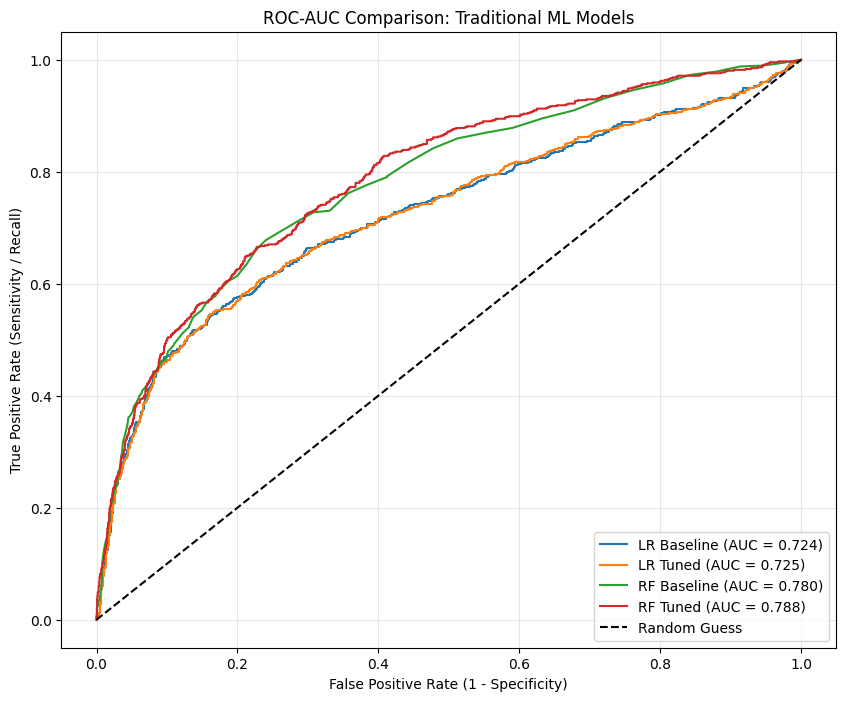

In [10]:
# Plot ROC Curves for all 4 experiments
plt.figure(figsize=(10, 8))

for prob, name in zip(
    [lr_prob_base, lr_prob_tuned, rf_prob_base, rf_prob_tuned],
    ["LR Baseline", "LR Tuned", "RF Baseline", "RF Tuned"]
):
    fpr, tpr, _ = roc_curve(y_val, prob)
    auc = roc_auc_score(y_val, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC-AUC Comparison: Traditional ML Models')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

# Deep Learning Implementation (Experiments 5–7)
In this section, we'll move to Deep Learning, implementing this with TensorFlow and Keras. We will make use of Batch Normalization and Dropout layers to avoid overfitting deep neural networks with tabular data.

As specified in the technical requirements, the first step is to convert our Pandas DataFrames into highly optimized objects of the tf.data.Dataset type. This allows for asynchronous data loading, prefetching and efficient batching.

In [11]:

# TensorFlow input pipeline
BATCH_SIZE = 64

X_train_tf = X_train_scaled.to_numpy(dtype=np.float32)
y_train_tf = y_train.to_numpy(dtype=np.float32)

X_val_tf = X_val_scaled.to_numpy(dtype=np.float32)
y_val_tf = y_val.to_numpy(dtype=np.float32)

X_test_tf = X_test_scaled.to_numpy(dtype=np.float32)
y_test_tf = y_test.to_numpy(dtype=np.float32)

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_tf, y_train_tf)
)
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_tf, y_val_tf)
)
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_tf, y_test_tf)
)

train_dataset = (
    train_dataset
    .shuffle(len(X_train_tf), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training, validation, and test pipelines created.")

Training, validation, and test pipelines created.


## Deep Learning Architectures via the Functional API
We will conduct three Deep Learning experiments:

* **Experiment 5**: Baseline Neural Network.

* **Experiment 6**: Tuned Network with Dropout and Early Stopping (Regularization).

* **Experiment 7**: Optimized Network with Class Weights (Handling Imbalance).

In [12]:
def build_dl_model(input_dim, dropout_rate=0.0):
    """Builds a Deep Learning model using the TensorFlow Functional API."""
    inputs = layers.Input(shape=(input_dim,))

    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(32, activation='relu')(x)

    # Sigmoid output for binary classification
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=[metrics.AUC(name='auc')]
    )
    return model

input_shape = X_train_tf.shape[1]

# Early stopping callback to prevent overfitting
early_stopping = callbacks.EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=10,
    restore_best_weights=True
)

## Executing the Deep Learning Experiments
We will train the models and track their performance. Notice how adding class_weight dynamically alters the loss function in Experiment 7, forcing the network to pay more attention to the minority (default) class.

In [13]:

# Calculate class weights using training labels only
neg, pos = np.bincount(y_train.to_numpy())
total = neg + pos

class_weights = {
    0: total / (2.0 * neg),
    1: total / (2.0 * pos)
}

# TensorBoard logs are written separately for each run for auditability.
LOG_ROOT = 'logs'
os.makedirs(LOG_ROOT, exist_ok=True)

def tb_callback(run_name):
    return callbacks.TensorBoard(log_dir=os.path.join(LOG_ROOT, run_name), histogram_freq=0)

# Experiment 5: Baseline neural network
print("Training Experiment 5: Baseline DL Model...")

dl_baseline = build_dl_model(input_shape, dropout_rate=0.0)

history_base = dl_baseline.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[tb_callback('experiment_5_baseline')],
    verbose=0
)

def log_dl_validation(model, name, experiment_id, params):
    y_prob = model.predict(val_dataset, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    row = {
        'Experiment': str(experiment_id),
        'Model': name,
        'ROC-AUC': float(roc_auc_score(y_val, y_prob)),
        'Average Precision': float(average_precision_score(y_val, y_prob)),
        'Accuracy': float(accuracy_score(y_val, y_pred)),
        'Default Precision': float(precision_score(y_val, y_pred, pos_label=1, zero_division=0)),
        'Default Recall': float(recall_score(y_val, y_pred, pos_label=1, zero_division=0)),
        'Default F1': float(f1_score(y_val, y_pred, pos_label=1, zero_division=0)),
        'Threshold': 0.5,
        'Parameters': str(params)
    }
    print(f'{name} validation metrics:', row)
    experiment_results.append(row)
    return row['ROC-AUC']

auc_base = log_dl_validation(dl_baseline, 'DL - Baseline', 5, {'layers': [128, 64, 32], 'dropout': 0.0, 'epochs': 20, 'class_weight': None})

# Experiment 6: Regularized neural network
print("Training Experiment 6: DL with Regularization...")

dl_tuned = build_dl_model(input_shape, dropout_rate=0.3)

history_tuned = dl_tuned.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    callbacks=[early_stopping, tb_callback('experiment_6_regularized')],
    verbose=0
)

auc_tuned = log_dl_validation(dl_tuned, 'DL - Regularized', 6, {'layers': [128, 64, 32], 'dropout': 0.3, 'early_stopping_patience': 10, 'class_weight': None})

# Experiment 7: Regularization plus class weighting
print("Training Experiment 7: DL with Class Weights...")

dl_optimized = build_dl_model(input_shape, dropout_rate=0.3)

history_opt = dl_optimized.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    callbacks=[early_stopping, tb_callback('experiment_7_class_weighted')],
    class_weight=class_weights,
    verbose=0
)

auc_opt = log_dl_validation(dl_optimized, 'DL - Class Weighted', 7, {'layers': [128, 64, 32], 'dropout': 0.3, 'early_stopping_patience': 10, 'class_weight': class_weights})

# Select the best neural network using validation ROC-AUC
dl_candidates = {
    'DL - Baseline': (auc_base, dl_baseline),
    'DL - Regularized': (auc_tuned, dl_tuned),
    'DL - Class Weighted': (auc_opt, dl_optimized)
}

best_dl_name, (best_dl_val_auc, best_dl_model) = max(
    dl_candidates.items(),
    key=lambda item: item[1][0]
)

best_dl_model.save('best_dl_model.keras')

print(f"\nBest DL model: {best_dl_name}")
print(f"Validation ROC-AUC: {best_dl_val_auc:.4f}")
print("Saved as best_dl_model.keras")


Training Experiment 5: Baseline DL Model...
DL - Baseline validation metrics: {'Experiment': '5', 'Model': 'DL - Baseline', 'ROC-AUC': 0.7702674997936952, 'Average Precision': 0.5513385977737539, 'Accuracy': 0.8163333333333334, 'Default Precision': 0.6506666666666666, 'Default Recall': 0.3674698795180723, 'Default F1': 0.46968238691049086, 'Threshold': 0.5, 'Parameters': "{'layers': [128, 64, 32], 'dropout': 0.0, 'epochs': 20, 'class_weight': None}"}
Training Experiment 6: DL with Regularization...
DL - Regularized validation metrics: {'Experiment': '6', 'Model': 'DL - Regularized', 'ROC-AUC': 0.7902767963979206, 'Average Precision': 0.5719374915214107, 'Accuracy': 0.8216666666666667, 'Default Precision': 0.6616541353383458, 'Default Recall': 0.39759036144578314, 'Default F1': 0.4967074317968015, 'Threshold': 0.5, 'Parameters': "{'layers': [128, 64, 32], 'dropout': 0.3, 'early_stopping_patience': 10, 'class_weight': None}"}
Training Experiment 7: DL with Class Weights...
DL - Class Wei

## Learning Curves Analysis

For all three neural-network experiments, the training and validation loss/AUC curves are plotted. These curves do not provide evidence of overfitting removal, but are rather diagnostic. Compare divergence with the other metrics that are held out and repeatability across seeds.


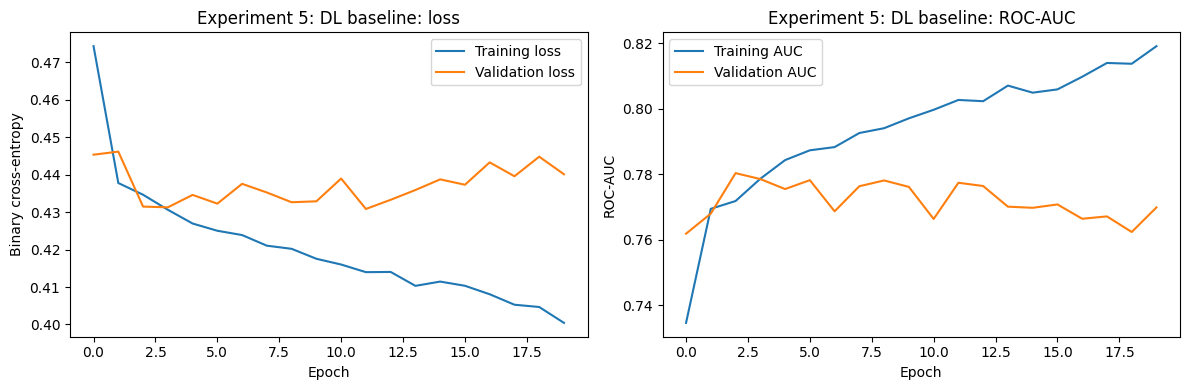

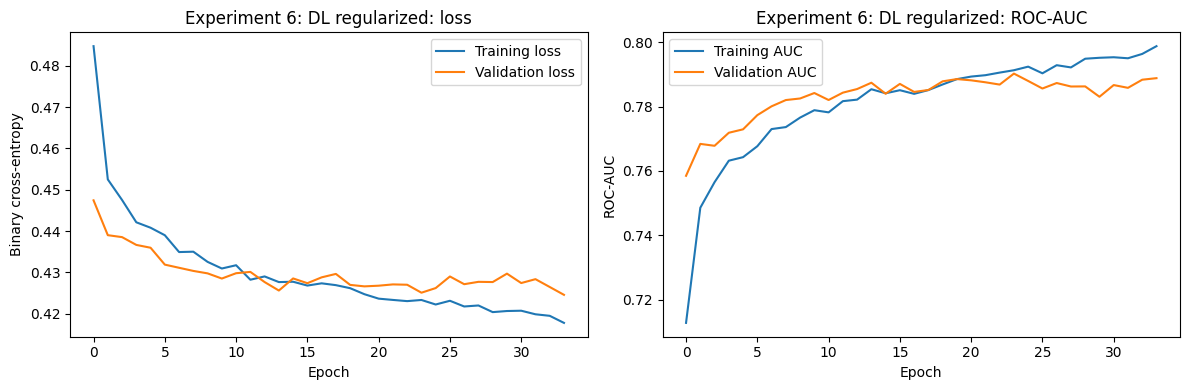

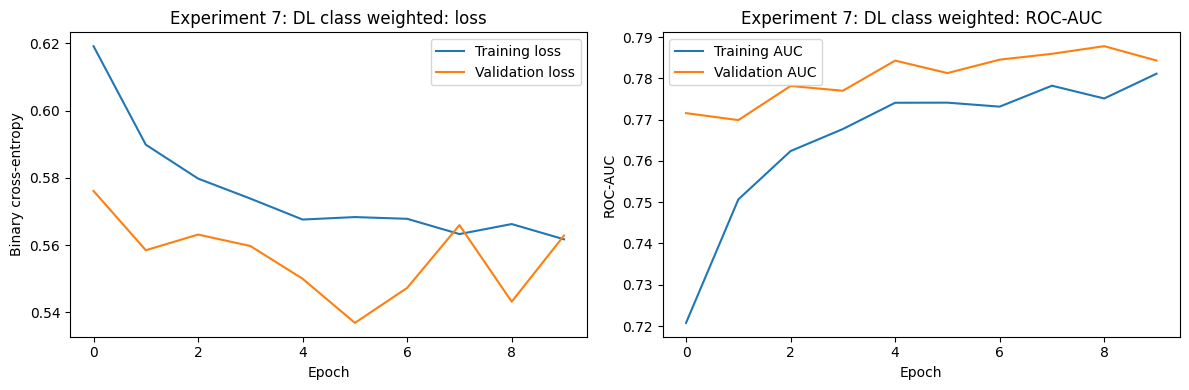

--- VALIDATION EXPERIMENT RESULTS (threshold metrics use 0.5) ---


,Experiment,Model,ROC-AUC,Average Precision,Accuracy,Default Precision,Default Recall,Default F1,Threshold,Parameters
0,6,DL - Regularized,0.7903,0.5719,0.8217,0.6617,0.3976,0.4967,0.5,"{'layers': [128, 64, 32], 'dropout': 0.3, 'ear..."
1,4,RF - Tuned,0.7876,0.5559,0.7830,0.5088,0.5663,0.5360,0.5,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
2,3,RF - Baseline,0.7798,0.5431,0.8203,0.6598,0.3886,0.4891,0.5,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
3,7,DL - Class Weighted,0.7718,0.5146,0.7427,0.4430,0.6325,0.5211,0.5,"{'layers': [128, 64, 32], 'dropout': 0.3, 'ear..."
4,5,DL - Baseline,0.7703,0.5513,0.8163,0.6507,0.3675,0.4697,0.5,"{'layers': [128, 64, 32], 'dropout': 0.0, 'epo..."
5,2,LR - Tuned,0.7247,0.4893,0.7157,0.4069,0.6220,0.4920,0.5,"{'C': 10, 'class_weight': 'balanced', 'dual': ..."
6,1,LR - Baseline,0.7242,0.4915,0.8113,0.6870,0.2711,0.3888,0.5,"{'C': 1.0, 'class_weight': None, 'dual': False..."


Saved experiment_results_validation.csv


In [14]:
# Learning Curves and Complete Experiment Table

# Learning curves are shown for each deep-learning run. AUC and loss should be interpreted together.

def plot_learning_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['loss'], label='Training loss')
    axes[0].plot(history.history['val_loss'], label='Validation loss')
    axes[0].set_title(f'{title}: loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Binary cross-entropy')
    axes[0].legend()

    axes[1].plot(history.history['auc'], label='Training AUC')
    axes[1].plot(history.history['val_auc'], label='Validation AUC')
    axes[1].set_title(f'{title}: ROC-AUC')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('ROC-AUC')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_learning_curves(history_base, 'Experiment 5: DL baseline')
plot_learning_curves(history_tuned, 'Experiment 6: DL regularized')
plot_learning_curves(history_opt, 'Experiment 7: DL class weighted')

results_df = pd.DataFrame(experiment_results)
results_df = results_df.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print('--- VALIDATION EXPERIMENT RESULTS (threshold metrics use 0.5) ---')
display(results_df.round(4))
results_df.to_csv('experiment_results_validation.csv', index=False)
print('Saved experiment_results_validation.csv')


Selected model: DL - Regularized
Validation ROC-AUC: 0.7903

Held-out test metrics:
Selected model: DL - Regularized
Threshold: 0.5000
Test ROC-AUC: 0.7777
Test average precision: 0.5554
Test accuracy: 0.8187
Test default precision: 0.6534
Test default recall: 0.3836
Test default F1: 0.4834

Test classification report:
              precision    recall  f1-score   support

           0     0.8433    0.9422    0.8900      4673
           1     0.6534    0.3836    0.4834      1327

    accuracy                         0.8187      6000
   macro avg     0.7484    0.6629    0.6867      6000
weighted avg     0.8013    0.8187    0.8001      6000

Confusion matrix (rows = true class [no default, default]; columns = predicted class [no default, default]):
[[4403  270]
 [ 818  509]]


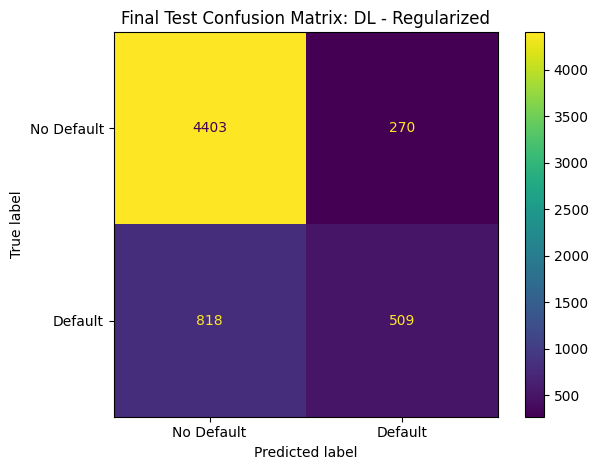

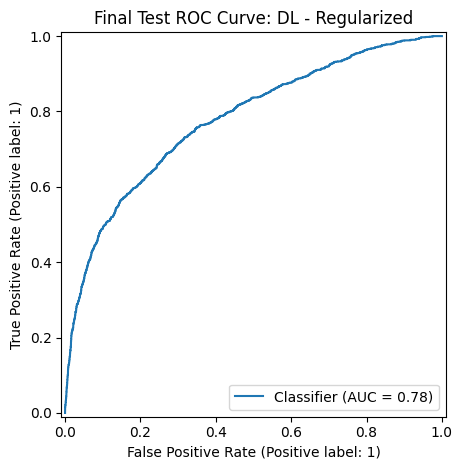

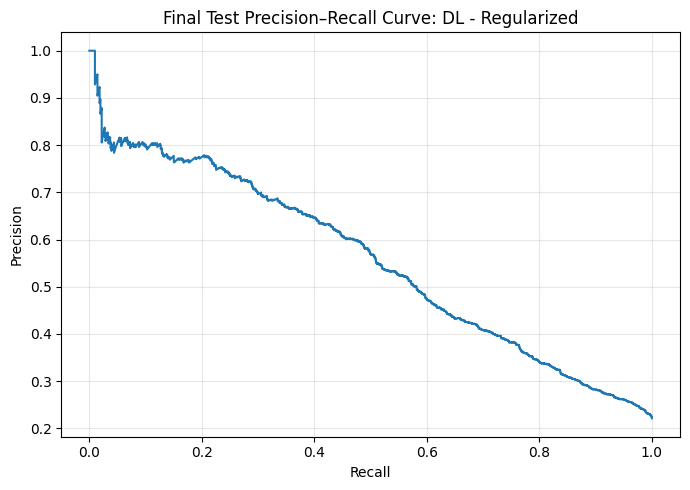

Saved selected model, preprocessing pipeline, feature columns, and final_test_metrics.json


In [15]:
# Final Selection and Held-Out Test Evaluation

# The winner is selected using validation ROC-AUC only. The test set is used once at a fixed 0.5 threshold.

from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve,
    average_precision_score, accuracy_score, precision_score, recall_score, f1_score
)
import matplotlib.pyplot as plt
import json
import joblib

model_lookup = {
    'LR - Baseline': lr_baseline,
    'LR - Tuned': lr_grid.best_estimator_,
    'RF - Baseline': rf_baseline,
    'RF - Tuned': rf_best,
    'DL - Baseline': dl_baseline,
    'DL - Regularized': dl_tuned,
    'DL - Class Weighted': dl_optimized
}

results_df = pd.DataFrame(experiment_results)
best_row = results_df.loc[results_df['ROC-AUC'].idxmax()]
best_name = best_row['Model']
best_model = model_lookup[best_name]
print('Selected model:', best_name)
print(f"Validation ROC-AUC: {best_row['ROC-AUC']:.4f}")

if best_name.startswith('DL -'):
    y_test_prob = best_model.predict(test_dataset, verbose=0).ravel()
else:
    y_test_prob = best_model.predict_proba(X_test_scaled)[:, 1]

threshold = 0.5
y_test_pred = (y_test_prob >= threshold).astype(int)
test_metrics = {
    'Selected model': best_name,
    'Threshold': threshold,
    'Test ROC-AUC': float(roc_auc_score(y_test, y_test_prob)),
    'Test average precision': float(average_precision_score(y_test, y_test_prob)),
    'Test accuracy': float(accuracy_score(y_test, y_test_pred)),
    'Test default precision': float(precision_score(y_test, y_test_pred, zero_division=0)),
    'Test default recall': float(recall_score(y_test, y_test_pred, zero_division=0)),
    'Test default F1': float(f1_score(y_test, y_test_pred, zero_division=0))
}
print('\nHeld-out test metrics:')
for k, v in test_metrics.items():
    print(f'{k}: {v:.4f}' if isinstance(v, float) else f'{k}: {v}')
print('\nTest classification report:')
print(classification_report(y_test, y_test_pred, digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_test_pred)
print('Confusion matrix (rows = true class [no default, default]; columns = predicted class [no default, default]):')
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default']).plot()
plt.title(f'Final Test Confusion Matrix: {best_name}')
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_test_prob)
plt.title(f'Final Test ROC Curve: {best_name}')
plt.tight_layout()
plt.show()

precision, recall, thresholds = precision_recall_curve(y_test, y_test_prob)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Final Test Precision–Recall Curve: {best_name}')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save the model together with preprocessing and feature order.
if best_name.startswith('DL -'):
    best_model.save('best_overall_model.keras')
else:
    joblib.dump(best_model, 'best_overall_model.pkl')
joblib.dump(preprocessor, 'preprocessor.joblib')
joblib.dump(list(X_train_scaled.columns), 'feature_columns.joblib')
test_metrics['Confusion matrix'] = cm.tolist()
with open('final_test_metrics.json', 'w') as f:
    json.dump(test_metrics, f, indent=2)
print('Saved selected model, preprocessing pipeline, feature columns, and final_test_metrics.json')


## Reproducibility, Experiment Tracking, and Artifact Checklist

Run the notebook from top to bottom and keep the resulting outputs along with the notebook:

experiment_results_validation.csv: Metrics for all seven validation experiments, including threshold-based default-class metrics, and recorded parameter settings.
`final_test_metrics.json`: Out-of-sample test metrics and confusion matrix for the model selected during validation.
The model artifacts are: best_traditional_model.pkl and best_overall_model.pkl (or best_overall_model.keras).
- best_dl_model.keras: the best neural network with the highest validation-AUC.
- `preprocessor.joblib`: Fitted transformation pipeline.
- `feature_columns.joblib`: Exact input order.
- `logs/`: TensorBoard event logs of the 3 experiments with deep learning.

Make sure to note down the versions of Python and packages used, source and version of the datasets, the seed, split sizes and any changes in the notebook. Basic tracking is done via TensorBoard logs and a csv experiment table — not to be confused with a managed tracking system like Weights & Biases or MLflow. Before submission, halt the runtime, rerun all cells in order and update the report by using the newly generated `experiment_results_validation.csv` and `final_test_metrics.json`. Old report scores are not allowed to be used if the preprocessing and cross-validation has changed.


## Responsible Use, Limitations, and Error Analysis

The positive class is default (1) and the default rate of the dataset is approximately 22%. This is not enough in terms of accuracy. Take a look at the ROC-AUC, average precision, default-class precision/recall/F1, the confusion matrix and the precision–recall curve together. Costs of false negative and false positive are not the same and cannot be determined without specifying a business cost model.

This project does not currently run subgroup fairness tests, calibration of probability, optimization of thresholds given a documented cost matrix, external validation or temporal validation. One-hot encoding for nominal categories, ordinal codes for payment-delay. The designed payment-to-bill ratio is capped, and it needs to be tested by ablation. Please don't use the benchmark results as a system to decide on production credit without domain review, fairness analysis, legal review, monitoring, explainability and human appeal processes.


In [ ]:
import os
import shutil

# Define the Google Drive destination path based on your setup
drive_dest_dir = '/content/drive/MyDrive/IML/Eloi_Iradukunda_Summative_Project'

# Create the folder in Google Drive if it doesn't exist
os.makedirs(drive_dest_dir, exist_ok=True)

# List of the specific artifact files your notebook generated
files_to_copy = [
    'experiment_results_validation.csv',
    'final_test_metrics.json',
    'preprocessor.joblib',
    'feature_columns.joblib',
    'best_overall_model.pkl',     # If XGBoost/RF won
    'best_overall_model.keras',   # If DL won
    'best_dl_model.keras'
]

# 1. Copy individual files
for file_name in files_to_copy:
    src_file = os.path.join('/content/', file_name)
    dst_file = os.path.join(drive_dest_dir, file_name)

    if os.path.exists(src_file):
        shutil.copy2(src_file, dst_file)
        print(f"Copied file: {file_name}")
    else:
        print(f"Skipped (not found): {file_name}")

# 2. Copy the entire 'logs' directory (for TensorBoard)
logs_src = '/content/logs'
logs_dst = os.path.join(drive_dest_dir, 'logs')

if os.path.exists(logs_src):
    shutil.copytree(logs_src, logs_dst, dirs_exist_ok=True)
    print("Copied directory: logs/")
else:
    print("Skipped (not found): logs/ directory")

print(f"\n All available assets successfully backed up to Google Drive at: {drive_dest_dir}")